# DOE-034
## POR トレンド確認

- 対象銘柄: 9984
- 実験計画: 完全実施要因計画 (Full Factorial Design)
- 実験パラメータ
    - PERIOD_MA_1  # 短周期移動平均線
        - 210, 240, 270
    - PERIOD_MA_2  # 長周期移動平均線
        - 1800, 2100, 2400
    - START_TRAILING  # トレーリング・ストップを開始する最大含み益
        - 10, 20, 30
    - THRESHOLD_TRAILING  # トレーリング・ストップのしきい値比
        - 0.7, 0.8, 0.9
    - FOLLOWING_MIN  # PTC 判定、順方向に 5 回以上更新されていて含み損になればロスカット
        - 2, 5, 8
- 固定パラメータ
    - TYPE_MA_1: EMA
    - START_TRAILING: 10  # トレーリング・ストップを開始する最大含み益
    - THRESHOLD_TRAILING: 0.9  # トレーリング・ストップのしきい値比
    - FOLLOWING_MIN: 5  # PTC 判定、順方向に 5 回以上更新されていて含み損になればロスカット
- MA1 / MA2 クロス・シグナルのエントリ・エグジット
    - クロス時に反対売買をしない。
- 評価指標
    - 収益と約定回数

In [6]:
from pathlib import Path

import pandas as pd

# === 実験番号 ===
name_doe = "doe-034"

# pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 400)

# 指定したディレクトリのPathオブジェクトを作成
dir_path = Path(f"../doe/{name_doe}")

# .glob() で .csv ファイルのリスト（イテレータ）を取得してリストに変換
list_csv_file = sorted([str(p) for p in dir_path.glob("*.csv") if p.is_file()])

# 集計対象の条件列
columns_group = [
    "PERIOD_MA_1",
    "PERIOD_MA_2",
    "START_TRAILING",
    "THRESHOLD_TRAILING",
    "FOLLOWING_MIN",
]

# CSV ファイルを読み込んで結合
df = pd.concat(
    [
        pd.read_csv(file).assign(
            DATE=pd.to_datetime(Path(file).stem[:8], format="%Y%m%d")
        )
        for file in list_csv_file
    ],
    ignore_index=True,
)

# 条件ごとに Profit を集計
df_total = df.groupby(columns_group, as_index=False).agg(
    Profit_Total=("Profit", "sum"),
    Profit_Mean=("Profit", "mean"),
    Profit_Median=("Profit", "median"),
    Transactions_Median=("Transactions", "median"),
)

print(df)
print("\nSummary Statistics")
print(df_total)
print("\n*** Past", len(list_csv_file), "days statistics ***")
print("\nProfit_Total Top 3")
print(df_total.nlargest(3, "Profit_Total"))
print("\nProfit_Total Bottom 3")
print(df_total.nsmallest(3, "Profit_Total"))
print("\n\nProfit_Median Top 3")
print(df_total.nlargest(3, "Profit_Median"))
print("\nProfit_Median Bottom 3")
print(df_total.nsmallest(3, "Profit_Median"))

     TYPE_MA_1  PERIOD_MA_1  PERIOD_MA_2  START_TRAILING  THRESHOLD_TRAILING  FOLLOWING_MIN  Profit  Transactions       DATE
0          EMA          210         1800              10                 0.7              2    -4.0          18.0 2026-09-01
1          EMA          240         1800              10                 0.7              2   -46.0          20.0 2026-09-01
2          EMA          270         1800              10                 0.7              2   -14.0          18.0 2026-09-01
3          EMA          210         2100              10                 0.7              2    11.0          12.0 2026-09-01
4          EMA          240         2100              10                 0.7              2   -14.0          12.0 2026-09-01
...        ...          ...          ...             ...                 ...            ...     ...           ...        ...
6556       EMA          240         2100              30                 0.9              8   -28.0           8.0 2026-10-13


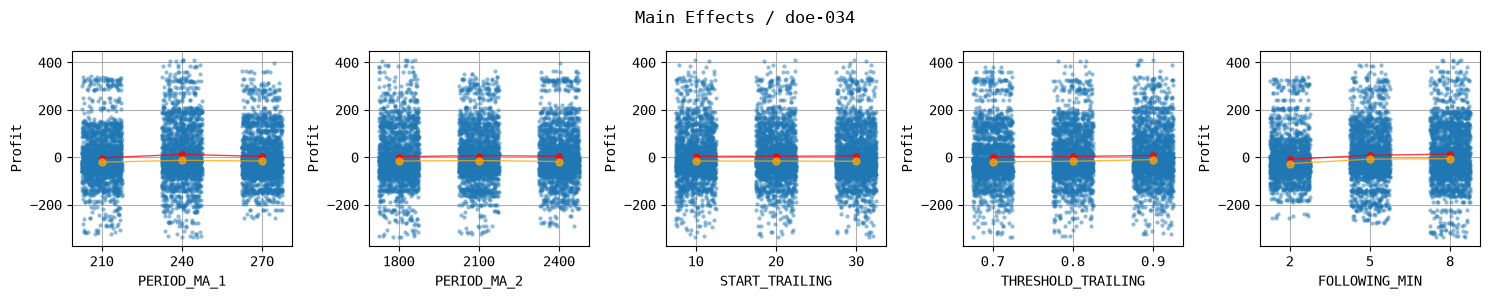

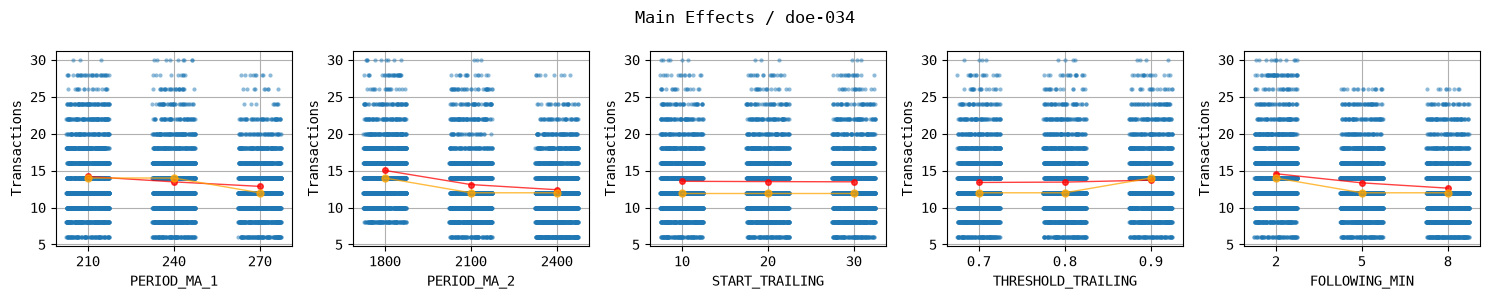

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "monospace"
# plt.rcParams["font.size"] = 11

cols_param = [
    "PERIOD_MA_1",
    "PERIOD_MA_2",
    "START_TRAILING",
    "THRESHOLD_TRAILING",
    "FOLLOWING_MIN",
]


for name_y in ["Profit", "Transactions"]:
    fig, axes = plt.subplots(1, 5, figsize=(15, 3))

    for ax, col in zip(axes, cols_param):
        sns.stripplot(
            data=df,
            x=col,
            y=name_y,
            size=3,
            jitter=0.25,  # 横方向へのばらつき具合
            alpha=0.5,  # 重なりが見やすいよう少し透明に
            color="tab:blue",  # 散布図の色を指定
            ax=ax,
        )

        # x の各水準ごとの平均値
        mean = df.groupby(col)[name_y].mean()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(mean)),
            mean.values,
            "o-",
            color="red",
            markersize=4,
            linewidth=1,
            alpha=0.75,
            zorder=5,  # 点の裏に隠れないよう前面に描画
        )

        # x の各水準ごとのメジアン
        median = df.groupby(col)[name_y].median()
        # stripplot の x 軸位置（0, 1, 2...）に合わせて線をつなぐ
        ax.plot(
            range(len(median)),
            median.values,
            "o-",
            color="orange",
            markersize=5,
            linewidth=1,
            alpha=0.75,
            zorder=5,
        )

        ax.set(xlabel=col, ylabel=name_y)
        ax.grid(True)

        # ax.set_title(f"Main Effect / {name_doe}")
    fig.suptitle(f"Main Effects / {name_doe}")

    plt.tight_layout()
    pngfile = f"../doe/{name_doe}/main_effect_{name_y}.png"
    plt.savefig(pngfile)
    plt.show()